# Week 2: Indicator practice

Exploration only. The real versions of these go into `src/idxlab/features/` in Week 6.

We compute three things on one stock (BBCA) from the sample data:
1. Daily return
2. 20-day simple moving average (SMA)
3. 14-day RSI

## 1. Load one stock

In [1]:
import pandas as pd

df = pd.read_parquet("../data/sample/prices_sample.parquet")
bbca = df[df["ticker"] == "BBCA"].sort_values("date").set_index("date")
print(bbca.shape)
bbca[["close"]].head()

(485, 9)


,close
date,
2022-01-03,6253.107910
2022-01-04,6317.133789
2022-01-05,6359.816406
2022-01-06,6381.157715
2022-01-07,6530.549805


## 2. Daily return

`pct_change()` gives (today / yesterday) - 1. A value of 0.01 means +1%.

In [2]:
bbca["return_1d"] = bbca["close"].pct_change()
bbca["return_1d"].describe()

count    484.000000
mean       0.000689
std        0.012908
min       -0.064616
25%       -0.006563
50%        0.000000
75%        0.007024
max        0.043228
Name: return_1d, dtype: float64

## 3. 20-day simple moving average

Average of the last 20 closes. The first 19 rows are NaN because there is not enough history yet.

<Axes: title={'center': 'BBCA close vs 20-day SMA'}, xlabel='date'>

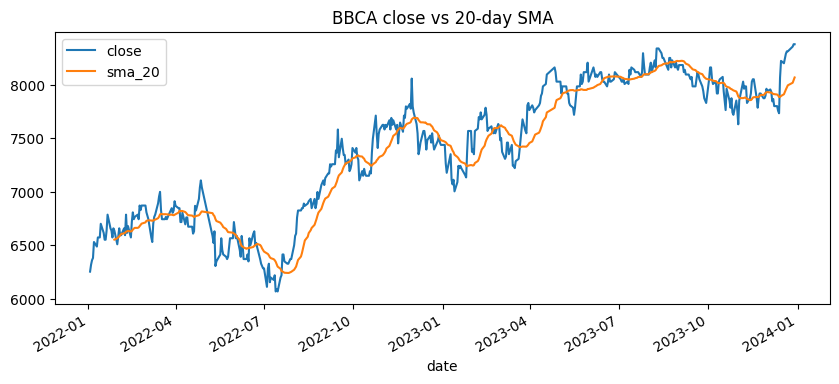

In [3]:
bbca["sma_20"] = bbca["close"].rolling(20).mean()
bbca[["close", "sma_20"]].plot(figsize=(10, 4), title="BBCA close vs 20-day SMA")

## 4. RSI (14-day)

RSI compares average gains to average losses over the last 14 days:

- `delta` = change in close from the previous day
- `gain` = average of the positive changes, `loss` = average of the negative changes (as positive numbers)
- `RSI = 100 - 100 / (1 + gain / loss)`

It always lies between 0 and 100. Above 70 is usually called overbought, below 30 oversold.

<Axes: title={'center': 'BBCA RSI (14-day, simple average)'}, xlabel='date'>

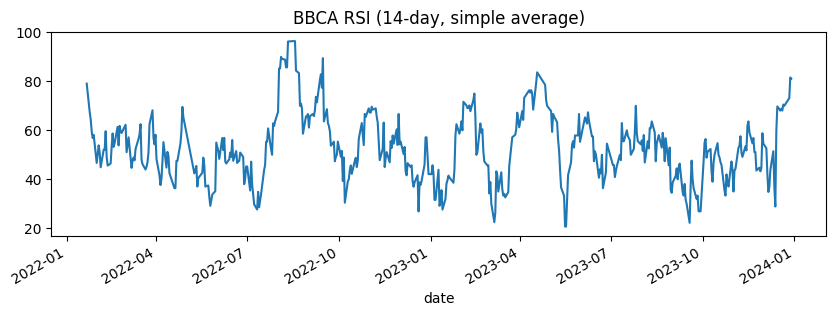

In [4]:
delta = bbca["close"].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
bbca["rsi_14"] = 100 - 100 / (1 + gain / loss)
bbca["rsi_14"].plot(figsize=(10, 3), title="BBCA RSI (14-day, simple average)")

## 5. Sanity checks

In [5]:
print("NaN in sma_20:", bbca["sma_20"].isna().sum(), "(expected 19)")
print("NaN in rsi_14:", bbca["rsi_14"].isna().sum(), "(expected 14)")
print("RSI min/max:", bbca["rsi_14"].min(), bbca["rsi_14"].max(), "(should be within 0-100)")
print("Largest daily move:", bbca["return_1d"].abs().max())
bbca[["close", "return_1d", "sma_20", "rsi_14"]].tail(10)

NaN in sma_20: 19 (expected 19)
NaN in rsi_14: 14 (expected 14)
RSI min/max: 20.68964732236357 96.42862029031694 (should be within 0-100)
Largest daily move: 0.06461550408504912


,close,return_1d,sma_20,rsi_14
date,,,,
2023-12-14,8070.433105,0.043228,7889.161279,59.656662
2023-12-15,8226.491211,0.019337,7897.770898,69.767253
2023-12-18,8204.198242,-0.002710,7914.141187,68.052143
2023-12-19,8248.784180,0.005435,7937.178369,68.822206
2023-12-20,8293.374023,0.005406,7958.007446,68.066999
2023-12-21,8315.667969,0.002688,7977.732422,70.516021
2023-12-22,8315.667969,0.000000,7997.457397,70.000093
2023-12-27,8360.254883,0.005362,8021.630518,73.170835
2023-12-28,8382.548828,0.002667,8046.918335,81.579031


## 6. Bonus: Wilder's RSI

The textbook RSI smooths with an exponential average (alpha = 1/14) instead of a plain rolling mean.
Compare the two lines. This is the version we will probably want in Week 6.

<Axes: title={'center': 'Simple vs Wilder RSI'}, xlabel='date'>

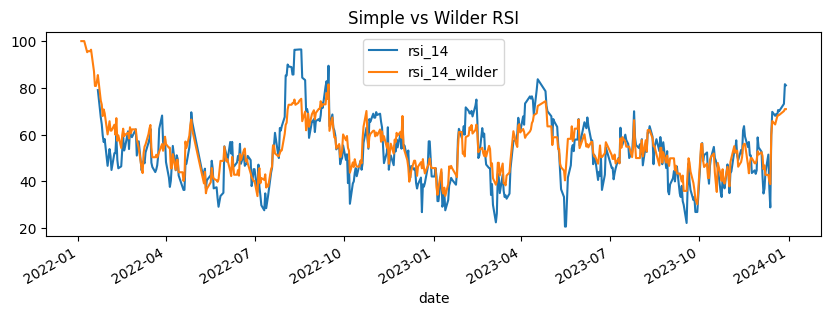

In [6]:
gain_w = delta.clip(lower=0).ewm(alpha=1/14, adjust=False).mean()
loss_w = (-delta.clip(upper=0)).ewm(alpha=1/14, adjust=False).mean()
bbca["rsi_14_wilder"] = 100 - 100 / (1 + gain_w / loss_w)

bbca[["rsi_14", "rsi_14_wilder"]].plot(figsize=(10, 3), title="Simple vs Wilder RSI")